## Given an tile, select galaxies within the tile coverage. --10-20-2026

In [1]:
import numpy as np
import healpy as hp
from astropy.table import Table
from astropy.coordinates import SkyCoord
from astropy.cosmology import FlatLambdaCDM
from astropy import units
from scipy.spatial import cKDTree
import matplotlib.pyplot as plt

In [2]:
# inner and outer radius in degree
radius_in_deg = 0.117 # deg
radius_out_deg = 0.599  

In [3]:
## load galaxy mock with r<20.5; the mock contains the host halo information 
idir = "/home/zjding/fiberassignment/JUST/BGS_mock/Junyu_mock/data/v1/"
filename = "lightcone_ra_0_90_dec_0_90_rmagcut20.5.fits"
ifile = idir + filename
gal_cat = Table.read(ifile)
gal_cat[0:10]

Mh,Mr,Ms,dec,gr,idx,index,mr,ra,type,z
float64,float64,float64,float64,float64,int64,int64,float64,float64,int64,float64
292610000000000.0,-23.18849199726835,11.462036032248465,41.29154120855546,0.19434165954589844,0,0,9.956809619034223,49.80819359215435,1,0.01465678246071711
288760000000.0,-19.147627035161182,9.6715072838076,40.941039034384545,0.8027172088623047,1,1,14.064473284463798,49.73535385617138,1,0.012097661239719004
30740000000.0,-14.319385075304051,7.428143526326751,41.99001360921037,0.3145475387573242,2,2,18.782163312338206,51.97146451013884,1,0.017620778481114208
46437000000.0,-14.599905494564513,7.399693165043393,39.507130787443195,0.09915733337402344,3,9,18.60793481161047,47.154312077790685,1,0.013867155944747855
162300000000000.0,-21.502181387099878,10.918396168536269,40.08326168476845,0.8249874114990234,4,13,13.64869346210335,68.4822249425556,1,0.035229356999005645
309360000000.0,-19.13669895226123,9.73882457127641,40.04117445714175,0.8425216674804688,5,14,16.02601552059702,67.55782079772624,1,0.03388702431135027
117070000000.0,-17.7034040264618,8.808032997480932,40.12613247990758,0.47997474670410156,6,17,17.42267235087408,68.84936724135324,1,0.03588234956204839
231530000000.0,-18.562923603360137,9.642383691131789,39.875325900528445,0.8497428894042969,7,18,16.59382801007962,67.53256098013837,1,0.03392400346502655
79792000000.0,-16.07441741201555,8.34817178537836,40.36759074556193,0.3656425476074219,8,19,19.054348508119194,68.4909460777121,1,0.03527082508276225


In [4]:
gal_ra = gal_cat["ra"]
gal_dec = gal_cat["dec"]
## Select galaxies close to the cluster center region (within rap)
gal_coords = SkyCoord(ra = gal_ra * units.deg, dec = gal_dec * units.deg)

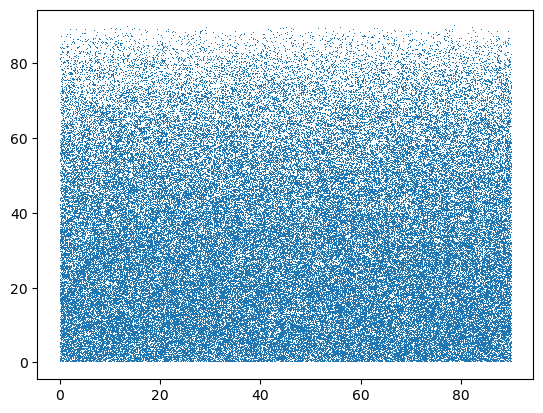

In [5]:
plt.plot(gal_ra[::100], gal_dec[::100], ",")

## load tiles

In [6]:
tile_path = "/home/zjding/fiberassignment/JUST/BGS_mock/Junyu_mock/fba/input/tiles_4passes.fits"
tiles = Table.read(tile_path)
tiles

RA,DEC,PASS,TILEID
float64,float64,int64,int64
45.174363782311545,11.323050539141434,0,100000
46.379520036802404,11.426781262661692,0,100001
44.684549138201966,10.239008843082686,0,100002
45.88518163747255,10.344646759839279,0,100003
47.585240265125016,11.529096934574866,0,100004
47.08634018109355,10.448905685477769,0,100005
48.79217871926838,11.621925259077202,0,100006
48.28869297014097,10.543713935957527,0,100007
46.89128681646389,12.50196535058943,0,100008


In [7]:
# Select tiles whose entire outer-radius disc lies inside the 0<RA<90, 0<DEC<90 footprint.
# On the sphere, a disc of angular radius radius_out_deg projects to a larger RA shift
# at high |DEC| because cos(dec) shrinks: dRA_max = radius_out_deg / cos(dec_center).
# We therefore use spherical margins for RA and Dec independently.
dec_tile = np.asarray(tiles["DEC"], dtype=np.float64)
ra_tile = np.asarray(tiles["RA"], dtype=np.float64)
cos_dec = np.cos(np.radians(dec_tile))
dra_out = np.where(cos_dec > 0, radius_out_deg / cos_dec, 1e6)
mask = (
    (tiles["TILEID"] < 200000)
    & (ra_tile - dra_out > 0.0)
    & (ra_tile + dra_out < 90.0)
    & (dec_tile - radius_out_deg > 0.0)
    & (dec_tile + radius_out_deg < 90.0)
)
tiles_sub = tiles[mask]
print(len(tiles_sub))


3964


In [8]:
tiles_sub

RA,DEC,PASS,TILEID
float64,float64,int64,int64
45.174363782311545,11.323050539141434,0,100000
46.379520036802404,11.426781262661692,0,100001
44.684549138201966,10.239008843082686,0,100002
45.88518163747255,10.344646759839279,0,100003
47.585240265125016,11.529096934574866,0,100004
47.08634018109355,10.448905685477769,0,100005
48.79217871926838,11.621925259077202,0,100006
48.28869297014097,10.543713935957527,0,100007
46.89128681646389,12.50196535058943,0,100008


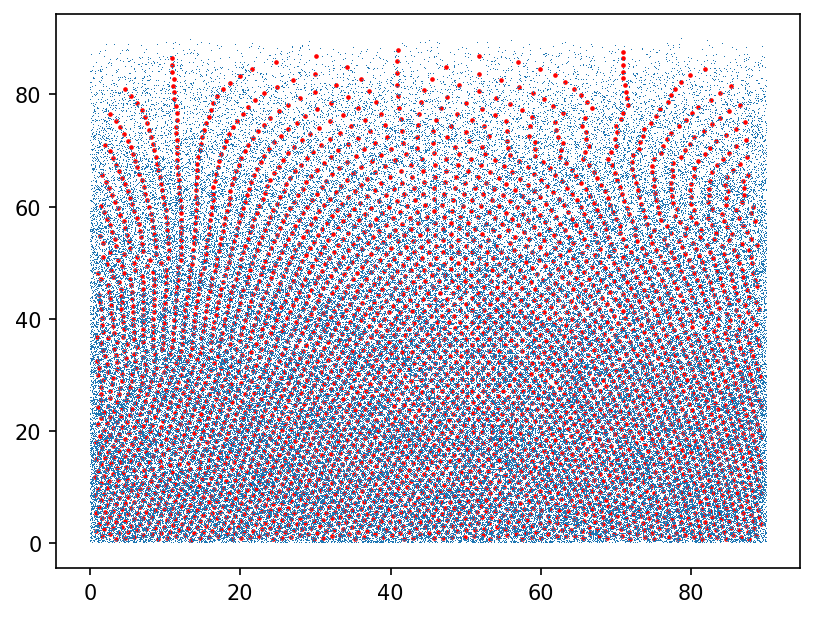

In [9]:
fig, ax = plt.subplots(dpi=150)
ax.plot(gal_ra[::100], gal_dec[::100], ",")
ax.scatter(tiles_sub["RA"], tiles_sub["DEC"], s=1.5, color="r")

In [10]:
tiles_ra = tiles_sub["RA"]
tiles_dec = tiles_sub["DEC"]
## Select galaxies within to the tile annulus region
tiles_coords = SkyCoord(ra = tiles_ra * units.deg, dec = tiles_dec * units.deg)

In [11]:
%%time
idx_gal_0, idx_tile_0, sep2d_0, _ = tiles_coords.search_around_sky(gal_coords, radius_in_deg * units.deg)

CPU times: user 8.7 s, sys: 1.44 s, total: 10.1 s
Wall time: 10.1 s


In [12]:
%%time
idx_gal_1, idx_tile_1, sep2d_1, _ = tiles_coords.search_around_sky(gal_coords, radius_out_deg * units.deg)

CPU times: user 19.4 s, sys: 2.41 s, total: 21.9 s
Wall time: 21.9 s


In [13]:
print(len(idx_gal_1), len(np.unique(idx_gal_1)))  ## there is slight overlap between tiles

11292717 11264554


In [14]:
%%time
# Split paired galaxy indices by tile index without a per-tile mask loop.
# Sorting idx_tile once and using np.split gives an O(N log N) vectorized split.
order = np.argsort(idx_tile_0, kind="mergesort")
idx_tile_sorted = idx_tile_0[order]
idx_gal_sorted = idx_gal_0[order]
unique_ic, split_points = np.unique(idx_tile_sorted, return_index=True)
ig_list_0 = np.split(idx_gal_sorted, split_points[1:])

order = np.argsort(idx_tile_1, kind="mergesort")
idx_tile_sorted = idx_tile_1[order]
idx_gal_sorted = idx_gal_1[order]
unique_ic, split_points = np.unique(idx_tile_sorted, return_index=True)
ig_list_1 = np.split(idx_gal_sorted, split_points[1:])

# Remove the inner-radius galaxy set (ig_list_0) from the outer-radius set (ig_list_1)
# for each tile, keeping only galaxies that lie in the tile annulus.
ig_intile_list = [
    np.setdiff1d(outer, inner, assume_unique=False).tolist()
    for inner, outer in zip(ig_list_0, ig_list_1)
]

CPU times: user 2.81 s, sys: 243 ms, total: 3.05 s
Wall time: 3.05 s


In [15]:
ig_sel = np.concatenate(ig_intile_list)
len(ig_sel)

10862960

(80.0, 90.0)

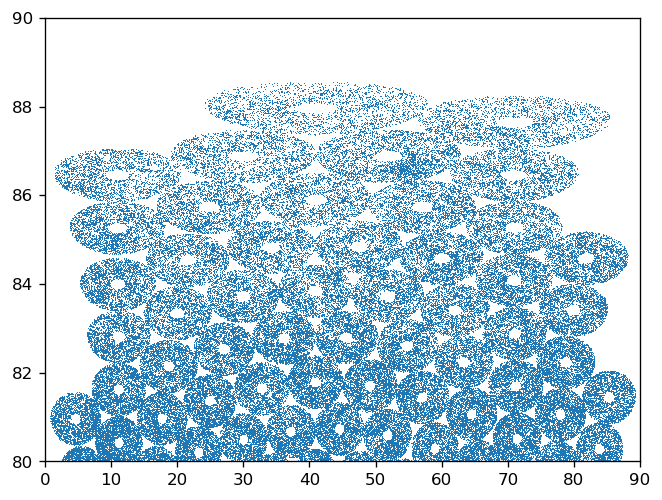

In [16]:
fig, ax = plt.subplots(dpi=120)
ax.plot(gal_cat["ra"][ig_sel], gal_cat["dec"][ig_sel], ",")
ax.set_xlim([0, 90])
ax.set_ylim([80, 90])

In [17]:
Nig_list = [len(i) for i in ig_intile_list]

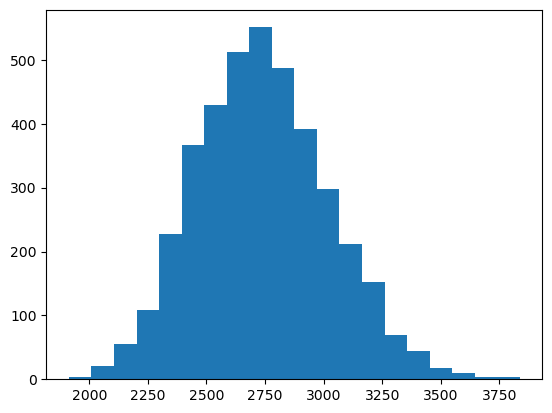

In [18]:
_ = plt.hist(Nig_list, bins=20)